# Notebook 4: Discovering Unknown Rate Laws from Spectra

The hardest version of kinetic modeling: only **spectra** are measured, the
pure-component **spectra are unknown**, and so are the **rate laws**. The
measured absorbance follows Beer-Lambert,

$$D(t, \lambda) = \sum_k c_k(t)\, s_k(\lambda) + \varepsilon, \qquad D = C S^\top + E,$$

so neither the concentrations $C$ nor the spectra $S$ are observed directly, and
no rate can be read off the data by differentiation.

This notebook combines model-free curve resolution,
[jaxsr](https://github.com/jkitchin/jaxsr) symbolic regression and kipetax:

1. **Resolve** the spectra into approximate concentration profiles without any
   kinetic model (MCR-ALS).
2. **Estimate rates** from those profiles and **discover** candidate rate laws
   with jaxsr.
3. **Refit** the candidates with kipetax against the raw spectra of all
   experiments, estimating the kinetics and the shared spectra $S$ together.
4. **Prune** terms that the refit shows to be negligible, and confirm with a
   BIC comparison of trajectory fits.

**Assumed known:** the stoichiometry (A → B and 2B → C, so
$dA/dt = -r_1$, $dB/dt = r_1 - 2r_2$, $dC/dt = r_2$) and the initial charge of
each experiment. **Unknown:** the rate laws $r_1, r_2$ and the spectra of A, B
and C.

Requires `pip install jaxsr` (tested with jaxsr 0.3.0).

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jax.numpy as jnp
import sympy as sp
from scipy.integrate import solve_ivp
from scipy.optimize import lsq_linear

import kipetax
from kipetax import ReactionModel, ReactionSet
from jaxsr import BasisLibrary, SymbolicRegressor, estimate_derivatives

## Synthetic experiments

The hidden "true" mechanism, used only to generate data and to grade the answer:
a saturating step $r_1 = k_1 A / (1 + K A)$ with $k_1 = 2$, $K = 1.5$, and a
second-order step $r_2 = k_2 B^2$ with $k_2 = 0.8$. Each species has two
absorption bands; the spectra overlap strongly, so no wavelength sees a single
species.

Four batch experiments with different initial charges are each recorded at 121
times and 40 wavelengths, with absorbance noise $\sigma = 0.005$. They are run on
one instrument, so all four share the same pure-component spectra.

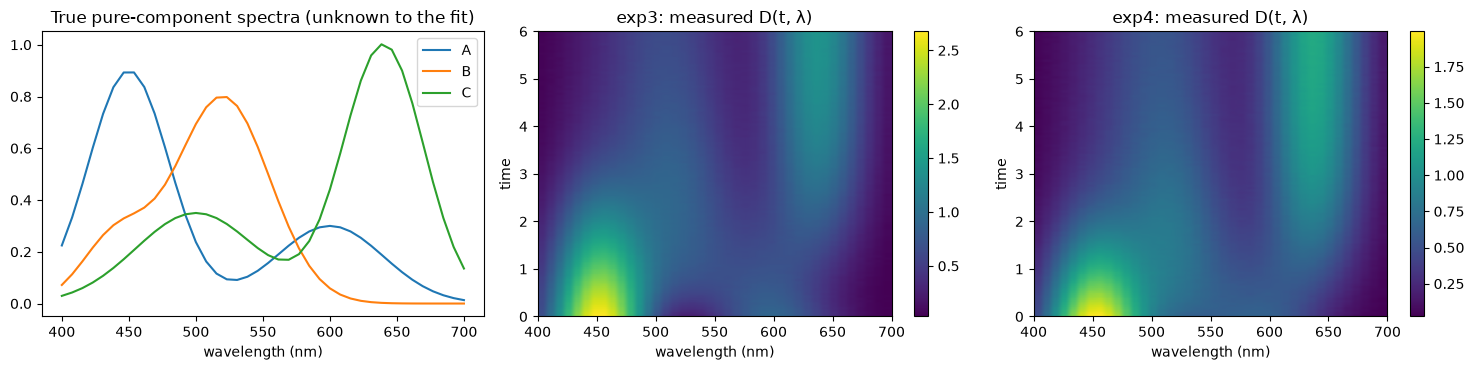

In [2]:
TRUE = {'k1': 2.0, 'K': 1.5, 'k2': 0.8}   # used only to grade the result


def true_rhs(t, y):
    A, B, C = y
    r1 = TRUE['k1'] * A / (1 + TRUE['K'] * A)
    r2 = TRUE['k2'] * B**2
    return [-r1, r1 - 2 * r2, r2]


EXPERIMENTS = {            # initial charge (A0, B0, C0)
    'exp1': (0.5, 0.0, 0.0),
    'exp2': (1.5, 0.0, 0.0),
    'exp3': (3.0, 0.0, 0.0),
    'exp4': (2.0, 0.6, 0.0),
}
SPECIES = ['A', 'B', 'C']
SIGMA = 0.005
t = np.linspace(0.0, 6.0, 121)
wl = np.linspace(400.0, 700.0, 40)


def band(center, width, height):
    return height * np.exp(-0.5 * ((wl - center) / width) ** 2)


S_true = pd.DataFrame({
    'A': band(450, 30, 0.9) + band(600, 40, 0.30),
    'B': band(520, 35, 0.8) + band(440, 25, 0.25),
    'C': band(640, 30, 1.0) + band(500, 45, 0.35),
}, index=wl)

rng = np.random.default_rng(3)
C_true, D = {}, {}
for name, y0 in EXPERIMENTS.items():
    sol = solve_ivp(true_rhs, (t[0], t[-1]), y0, t_eval=t, rtol=1e-10, atol=1e-12)
    C_true[name] = pd.DataFrame(sol.y.T, index=t, columns=SPECIES)
    D[name] = pd.DataFrame(sol.y.T @ S_true.values.T + rng.normal(0, SIGMA, (len(t), len(wl))),
                           index=t, columns=wl)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
S_true.plot(ax=axes[0], title='True pure-component spectra (unknown to the fit)')
axes[0].set_xlabel('wavelength (nm)')
for ax, name in zip(axes[1:], ['exp3', 'exp4']):
    im = ax.imshow(D[name].values, aspect='auto', origin='lower', cmap='viridis',
                   extent=[wl[0], wl[-1], t[0], t[-1]])
    ax.set_title(f'{name}: measured D(t, λ)')
    ax.set_xlabel('wavelength (nm)')
    ax.set_ylabel('time')
    plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

## Step 1: Model-free resolution (MCR-ALS)

Multivariate curve resolution by alternating least squares factors $D \approx
C S^\top$ without a kinetic model. Stacking the four experiments on top of each
other (they share $S$) gives one augmented matrix, and the iterations alternate
two constrained least-squares solves:

- for $C$, row by row: concentrations are non-negative, satisfy the mass balance
  $A + B + 2C = A_0 + B_0$ of their experiment, and the first row of each
  experiment is the known initial charge;
- for $S$, column by column: absorptivities are non-negative.

Stacking experiments with different initial compositions is the standard way to
reduce the rotational ambiguity of curve resolution. It does not remove it.

In [3]:
def mcr_als(D, experiments, max_iter=2000, tol=1e-9, closure_weight=10.0):
    names = list(experiments)
    n_t = len(D[names[0]])
    Daug = np.vstack([D[n].values for n in names])
    w = np.array([1.0, 1.0, 2.0])                              # A + B + 2C conserved
    total = np.concatenate([np.full(n_t, w @ np.array(experiments[n])) for n in names])
    known = {i * n_t: np.array(experiments[n], float) for i, n in enumerate(names)}

    def solve_C(S):
        lhs = np.vstack([S, closure_weight * w])
        C = np.empty((Daug.shape[0], 3))
        for i, row in enumerate(Daug):
            C[i] = known[i] if i in known else lsq_linear(
                lhs, np.append(row, closure_weight * total[i]), bounds=(0, np.inf)).x
        return C

    def solve_S(C):
        return np.column_stack([lsq_linear(C, Daug[:, j], bounds=(0, np.inf)).x
                                for j in range(Daug.shape[1])]).T

    # Start S from spectra recorded at three stages of the reaction: pure A
    # (t = 0 of exp3, divided by its charge), mid-reaction in exp2, and the end
    # of exp3 (mostly C).
    i2, i3 = names.index('exp2') * n_t, names.index('exp3') * n_t
    S = np.column_stack([Daug[i3] / experiments['exp3'][0], Daug[i2 + 30], Daug[i3 + n_t - 1]])
    previous = np.inf
    for it in range(1, max_iter + 1):
        C = solve_C(S)
        S = solve_S(C)
        lof = np.linalg.norm(Daug - C @ S.T)
        if abs(previous - lof) < tol * lof:
            break
        previous = lof
    C_hat = {n: pd.DataFrame(C[i * n_t:(i + 1) * n_t], index=D[n].index, columns=SPECIES)
             for i, n in enumerate(names)}
    return C_hat, pd.DataFrame(S, index=D[names[0]].columns, columns=SPECIES), it, lof / np.sqrt(Daug.size)


C_mcr, S_mcr, iters, rms = mcr_als(D, EXPERIMENTS)
print(f'MCR-ALS: {iters} iterations, residual RMS {rms:.4f} (noise sigma {SIGMA})')
err = pd.concat([C_mcr[n] - C_true[n] for n in EXPERIMENTS])
print('concentration error RMS:', dict(zip(SPECIES, np.sqrt((err**2).mean()).round(3))))

MCR-ALS: 901 iterations, residual RMS 0.0048 (noise sigma 0.005)
concentration error RMS: {'A': 0.106, 'B': 0.072, 'C': 0.017}


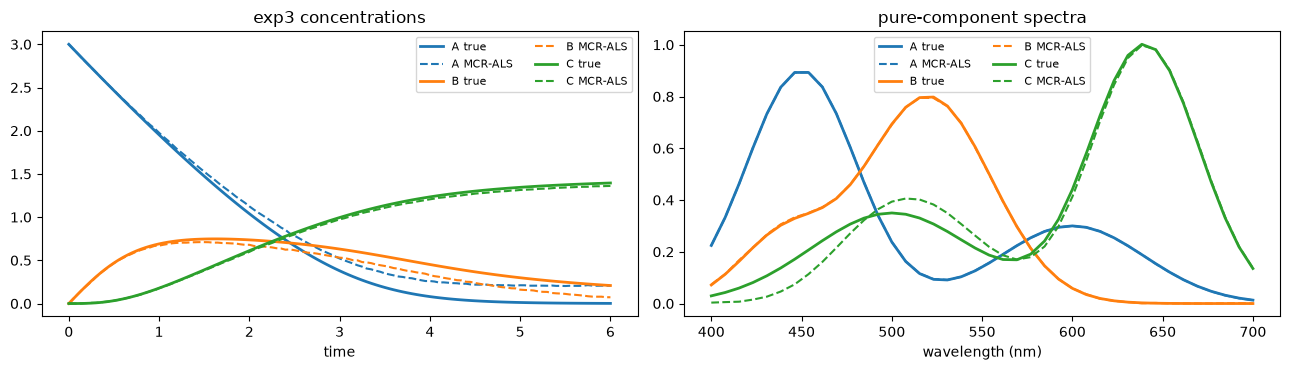

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
colors = dict(zip(SPECIES, ['tab:blue', 'tab:orange', 'tab:green']))
for k in SPECIES:
    axes[0].plot(t, C_true['exp3'][k], '-', color=colors[k], lw=2, label=f'{k} true')
    axes[0].plot(t, C_mcr['exp3'][k], '--', color=colors[k], label=f'{k} MCR-ALS')
    axes[1].plot(wl, S_true[k], '-', color=colors[k], lw=2, label=f'{k} true')
    axes[1].plot(wl, S_mcr[k], '--', color=colors[k], label=f'{k} MCR-ALS')
axes[0].set(title='exp3 concentrations', xlabel='time')
axes[1].set(title='pure-component spectra', xlabel='wavelength (nm)')
for ax in axes:
    ax.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

MCR-ALS converges, and its factorization reproduces the data to the noise level
(residual RMS 0.0048 against $\sigma = 0.005$). Yet the profiles are wrong: the
concentration of A is off by about 0.11 RMS and B by 0.07, and the recovered
spectrum of C is off by up to 0.10. This is rotational ambiguity. Other pairs
$(C, S)$ satisfy every constraint and fit the data equally well, and a
model-free method has no way to choose among them. Running more iterations does
not help: the algorithm has converged to one member of that family.

## Step 2: Rates and candidate rate laws

Rates come from the resolved profiles through the stoichiometry,
$r_1 = -dA/dt$ and $r_2 = dC/dt$, by Savitzky-Golay differentiation. jaxsr then
picks each law from a library of chemically sensible terms: every candidate for a
rate contains that reaction's reactant, and the library offers competing
mechanisms (first or second order, saturation, inhibition by each species). Inner
constants such as the $K$ of a saturation term are fitted by profile likelihood.

In [5]:
K_RANGE = {'K': (0.05, 20.0)}
NAMES = ['A', 'B', 'C']


def library_r1():
    lib = BasisLibrary(n_features=3, feature_names=NAMES)
    lib.add_custom('A',   lambda X: X[:, 0],           complexity=1, feature_indices=(0,))
    lib.add_custom('A^2', lambda X: X[:, 0]**2,        complexity=2, feature_indices=(0,))
    lib.add_custom('A*B', lambda X: X[:, 0] * X[:, 1], complexity=2, feature_indices=(0, 1))
    lib.add_custom('A*C', lambda X: X[:, 0] * X[:, 2], complexity=2, feature_indices=(0, 2))
    lib.add_parametric('A/(1+K*A)', lambda X, K: X[:, 0] / (1 + K * X[:, 0]),
                       K_RANGE, feature_indices=(0,), log_scale=True)    # saturation
    lib.add_parametric('A/(1+K*B)', lambda X, K: X[:, 0] / (1 + K * X[:, 1]),
                       K_RANGE, feature_indices=(0, 1), log_scale=True)  # inhibition by B
    lib.add_parametric('A/(1+K*C)', lambda X, K: X[:, 0] / (1 + K * X[:, 2]),
                       K_RANGE, feature_indices=(0, 2), log_scale=True)  # inhibition by C
    return lib


def library_r2():
    lib = BasisLibrary(n_features=3, feature_names=NAMES)
    lib.add_custom('B',   lambda X: X[:, 1],           complexity=1, feature_indices=(1,))
    lib.add_custom('B^2', lambda X: X[:, 1]**2,        complexity=2, feature_indices=(1,))
    lib.add_custom('A*B', lambda X: X[:, 0] * X[:, 1], complexity=2, feature_indices=(0, 1))
    lib.add_custom('B*C', lambda X: X[:, 1] * X[:, 2], complexity=2, feature_indices=(1, 2))
    lib.add_parametric('B/(1+K*B)', lambda X, K: X[:, 1] / (1 + K * X[:, 1]),
                       K_RANGE, feature_indices=(1,), log_scale=True)
    lib.add_parametric('B^2/(1+K*B)', lambda X, K: X[:, 1]**2 / (1 + K * X[:, 1]),
                       K_RANGE, feature_indices=(1,), log_scale=True)
    return lib


def estimate_rates(C_profiles, window=21):
    X, r1, r2 = [], [], []
    for df in C_profiles.values():
        dC = estimate_derivatives(df[SPECIES].values, df.index.values, method='savgol',
                                  window_length=window, polyorder=3)
        X.append(df[SPECIES].values)
        r1.append(-dC[:, 0])
        r2.append(dC[:, 2])
    return np.vstack(X), np.concatenate(r1), np.concatenate(r2)


def discover(library, X, y, max_terms=3):
    model = SymbolicRegressor(basis_library=library, max_terms=max_terms,
                              strategy='greedy_forward', information_criterion='bic')
    model.fit(jnp.asarray(X), jnp.asarray(y))
    return model


X, r1_est, r2_est = estimate_rates(C_mcr)
sr_r1 = discover(library_r1(), X, r1_est)
sr_r2 = discover(library_r2(), X, r2_est)
print('jaxsr r1 =', sr_r1.expression_[4:])
print('jaxsr r2 =', sr_r2.expression_[4:])

jaxsr r1 = 3.992*A/(1+0.08213*A) - 0.3223*A*C - 2.882*A
jaxsr r2 = 0.7675*B^2/(1+0.05606*B) + 0.1928*B*C + 0.01168*A*B


Both proposals are wrong in instructive ways. Each contains a term of the right
kind, but the distorted profiles push the fit into compensating terms: $r_1$
gains two negative corrections and a saturation constant near 0.08 instead of
1.5, and $r_2$ gains a weak saturation and two cross terms. jaxsr is doing its
job on the data it was given; the resolved concentrations are what is off. Treat
its output as a short list of candidate terms, not as the answer.

## Step 3: From jaxsr expressions to kipetax models

Each discovered law is summed term by term into a SymPy expression, and every
floating-point constant becomes a named, non-negative kipetax parameter seeded at
the jaxsr value (its sign stays in the expression). The lower bound of 0 lets the
refit switch off a term the data do not support.

In [6]:
def as_sympy(model):
    """Sum a fitted jaxsr model's terms into a SymPy expression, term by term."""
    return sum(float(c) * sp.sympify(name.replace('^', '**'))
               for name, c in zip(model.selected_features_, model.coefficients_))


def parametrize(expr, prefix):
    """Replace each numeric constant in ``expr`` by a symbol ``<prefix>_<i>``.

    Returns the template expression and ``{name: (magnitude, sign)}`` seeds.
    Integer-valued exponents are made exact so they are not treated as constants.
    """
    expr = expr.replace(
        lambda e: e.is_Pow and e.exp.is_Float and float(e.exp).is_integer(),
        lambda e: sp.Pow(e.base, int(e.exp)))
    seeds, subs = {}, {}
    for f in sorted(expr.atoms(sp.Float), key=sp.default_sort_key):
        name = f'{prefix}_{len(seeds) + 1}'
        value = float(f)
        seeds[name] = (abs(value), 1 if value >= 0 else -1)
        subs[f] = (1 if value >= 0 else -1) * sp.Symbol(name)
    return expr.xreplace(subs), seeds


def to_kipetax(expr, env):
    """Rebuild a SymPy expression from kipetax variables and math functions."""
    if expr.is_Symbol:
        return env[str(expr)]
    if expr.is_Integer:
        return int(expr)
    if expr.is_Number:
        return float(expr)
    args = [to_kipetax(a, env) for a in expr.args]
    if expr.is_Add:
        out = args[0]
        for a in args[1:]:
            out = out + a
        return out
    if expr.is_Mul:
        out = args[0]
        for a in args[1:]:
            out = out * a
        return out
    if expr.is_Pow:
        return args[0] ** args[1]
    if expr.func is sp.exp:
        return kipetax.exp(args[0])
    if expr.func is sp.log:
        return kipetax.log(args[0])
    raise NotImplementedError(f'no kipetax equivalent for {expr.func}')


tmpl_r1, seeds_r1 = parametrize(as_sympy(sr_r1), 'r1')
tmpl_r2, seeds_r2 = parametrize(as_sympy(sr_r2), 'r2')
print('r1 =', tmpl_r1)
print('r2 =', tmpl_r2)

r1 = -A*C*r1_2 - A*r1_1 + A*r1_4/(A*r1_3 + 1)
r2 = A*B*r2_1 + B**2*r2_4/(B*r2_2 + 1) + B*C*r2_3


## Step 4: Refit against the raw spectra

One `ReactionModel` per experiment, with its own initial charge and spectral data,
all declaring the same parameter names, joined in a `ReactionSet`. With
`shared_spectra=True` the four experiments share one set of pure-component spectra
$S$, estimated together with the kinetics. That is exactly what curve resolution
lacked: the kinetic model ties the concentration profiles together, and the
shared spectra tie the experiments together, which removes the rotational freedom
that left MCR-ALS ambiguous.

The fit uses every second time point (61 per experiment, 9760 absorbance
values). BIC from a trajectory fit is $\chi^2 + p \ln n$ with $p$ the number of
kinetic parameters; the spectra add the same number of parameters to every
candidate, so they cancel in comparisons.

In [7]:
STRIDE = 2


def refit(templates, seeds, name):
    rs = ReactionSet(name)
    for exp_name, y0 in EXPERIMENTS.items():
        r = ReactionModel(exp_name)
        env = {p: r.parameter(p, value=mag, bounds=(0.0, max(10 * mag, 1.0)))
               for p, (mag, _sign) in seeds.items()}
        for comp, c0 in zip(SPECIES, y0):
            env[comp] = r.component(comp, value=float(c0))
        rate1 = to_kipetax(templates['r1'], env)
        rate2 = to_kipetax(templates['r2'], env)
        r.add_ode('A', -rate1)
        r.add_ode('B', rate1 - 2 * rate2)
        r.add_ode('C', rate2)
        r.add_data(name='D', data=D[exp_name].iloc[::STRIDE], category='spectral')
        r.set_discretization(nfe=30, ncp=3)
        rs.add_model(r)
    ro = rs.run_opt(variances={'device': SIGMA**2}, shared_spectra=True)
    ro.n = sum(D[n].iloc[::STRIDE].size for n in EXPERIMENTS)
    ro.p = len(seeds)
    ro.bic = ro.objective + ro.p * np.log(ro.n)
    ro.templates = dict(templates)
    return ro


full = refit({'r1': tmpl_r1, 'r2': tmpl_r2}, {**seeds_r1, **seeds_r2}, 'jaxsr_candidates')
print(f'\nchi^2 = {full.objective:.0f} for {full.n} absorbance values, '
      f'{full.p} kinetic parameters, BIC = {full.bic:.1f}')


chi^2 = 9609 for 9760 absorbance values, 8 kinetic parameters, BIC = 9682.9


## Step 5: Prune, then confirm with BIC

The refit says how much each part of each rate law actually contributes. Along
the fitted concentration trajectories, measure the largest change in the rate
when a part is removed: an additive term, or a saturation constant set to zero.
Parts that change their rate by less than 5% anywhere are dropped, and the pruned
model is refit.

In [8]:
A_, B_, C_ = sp.symbols('A B C')


def relative_effect(full_expr, reduced_expr, values, Z):
    f = sp.lambdify((A_, B_, C_), full_expr.subs(values), 'numpy')
    g = sp.lambdify((A_, B_, C_), reduced_expr.subs(values), 'numpy')
    a = np.broadcast_to(f(*Z.T), (len(Z),))
    b = np.broadcast_to(g(*Z.T), (len(Z),))
    return np.max(np.abs(a - b)) / np.max(np.abs(a))


def removable_parts(expr):
    """(label, reduced expression) for each additive term and each denominator constant."""
    expr = sp.expand(expr)
    parts = []
    terms = sp.Add.make_args(expr)
    if len(terms) > 1:
        parts += [(f'term {term}', expr - term) for term in terms]
    for s in sp.fraction(sp.together(expr))[1].free_symbols - {A_, B_, C_}:
        parts.append((f'{s} -> 0', expr.subs(s, 0)))
    return parts


def prune(expr, fit, tol=0.05):
    values = {sp.Symbol(k): float(v) for k, v in fit.P.items()}
    Z = np.vstack([fit.experiments[n].Z[SPECIES].values for n in EXPERIMENTS])
    dropped = []
    while True:
        scored = sorted((relative_effect(expr, red, values, Z), label, red)
                        for label, red in removable_parts(expr))
        if not scored or scored[0][0] >= tol:
            return sp.expand(expr), dropped
        effect, label, expr = scored[0]
        dropped.append(f'{label} (changes the rate by {100 * effect:.2f}%)')


def reseed(templates, fit):
    names = set().union(*(e.free_symbols for e in templates.values())) - {A_, B_, C_}
    return {str(s): (float(fit.P[str(s)]), 1) for s in names}


pruned_t = {}
for rate in ('r1', 'r2'):
    pruned_t[rate], dropped = prune(full.templates[rate], full)
    print(f'{rate}: {pruned_t[rate]}')
    for d in dropped:
        print('    dropped', d)

pruned = refit(pruned_t, reseed(pruned_t, full), 'pruned')
print(f'\npruned: chi^2 = {pruned.objective:.0f}, p = {pruned.p}, BIC = {pruned.bic:.1f}'
      f'   (all jaxsr terms: BIC = {full.bic:.1f})')

r1: A*r1_4/(A*r1_3 + 1)
    dropped term -A*r1_1 (changes the rate by 0.00%)
    dropped term -A*C*r1_2 (changes the rate by 0.12%)
r2: B**2*r2_4 + B*C*r2_3
    dropped term A*B*r2_1 (changes the rate by 0.14%)
    dropped r2_2 -> 0 (changes the rate by 0.31%)



pruned: chi^2 = 9610, p = 4, BIC = 9647.2   (all jaxsr terms: BIC = 9682.9)


A part can matter by more than 5% and still not be needed. Test what is left the
other way round: for each rate that still has more than one term, refit without
its weakest term and keep the removal if BIC improves.

In [9]:
model = pruned
while True:
    values = {sp.Symbol(k): float(v) for k, v in model.P.items()}
    Z = np.vstack([model.experiments[n].Z[SPECIES].values for n in EXPERIMENTS])
    trials = []
    for rate, expr in model.templates.items():
        terms = sp.Add.make_args(sp.expand(expr))
        if len(terms) > 1:
            effect, term = min((relative_effect(expr, expr - term, values, Z), term) for term in terms)
            trials.append((rate, term))
    best = None
    for rate, term in trials:
        cand_t = dict(model.templates)
        cand_t[rate] = sp.expand(model.templates[rate] - term)
        cand = refit(cand_t, reseed(cand_t, model), f'without_{rate}')
        print(f'without {term} in {rate}: chi^2 = {cand.objective:.0f}, BIC = {cand.bic:.1f} '
              f'(current {model.bic:.1f})')
        if cand.bic < model.bic and (best is None or cand.bic < best.bic):
            best = cand
    if best is None:
        break
    model = best

final = model
print('\nfinal model:')
for rate, expr in final.templates.items():
    print(f'  {rate} = {expr}')

without B*C*r2_3 in r2: chi^2 = 9611, BIC = 9638.8 (current 9647.2)

final model:
  r1 = A*r1_4/(A*r1_3 + 1)
  r2 = B**2*r2_4


## Result

Starting from jaxsr's eight-parameter proposal, the refit on the raw spectra,
pruning and one BIC test arrive at exactly the true forms,
$r_1 = k_1 A / (1 + KA)$ and $r_2 = k_2 B^2$. Pruning removed four parts that
changed their rate by 0.3% or less. The $BC$ term in $r_2$ was larger than the 5%
pruning threshold, yet removing it raised $\chi^2$ by only about 1 while saving
a parameter, so BIC fell from 9647.2 to 9638.8.

The rate constants come out within 0.4% of the truth, $\chi^2 = 9611$ for 9760
absorbance values is what the noise level predicts, and the recovered spectra
are accurate to 0.004 absorbance units, against errors up to 0.10 from MCR-ALS.

In [10]:
SYM = set(sp.symbols('A B C'))


def rate_constant_names(t1, t2):
    num, den = sp.fraction(sp.together(t1))
    k1, K, k2 = num.free_symbols - SYM, den.free_symbols - SYM, t2.free_symbols - SYM
    if not (len(k1) == len(K) == len(k2) == 1):
        raise ValueError(f'not the k1*A/(1+K*A), k2*B**2 forms: {t1}, {t2}')
    return {'k1': str(k1.pop()), 'K': str(K.pop()), 'k2': str(k2.pop())}


names = rate_constant_names(final.templates['r1'], final.templates['r2'])
result = pd.DataFrame({'true': TRUE,
                       'kipetax (from spectra)': {k: float(final.P[n]) for k, n in names.items()}})
result['error %'] = 100 * (result['kipetax (from spectra)'] / result['true'] - 1)
print(f'chi^2 = {final.objective:.0f} for {final.n} absorbance values')
result.round(4)

chi^2 = 9611 for 9760 absorbance values


,true,kipetax (from spectra),error %
k1,2.0,1.9996,-0.0180
K,1.5,1.4997,-0.0223
k2,0.8,0.8033,0.4101


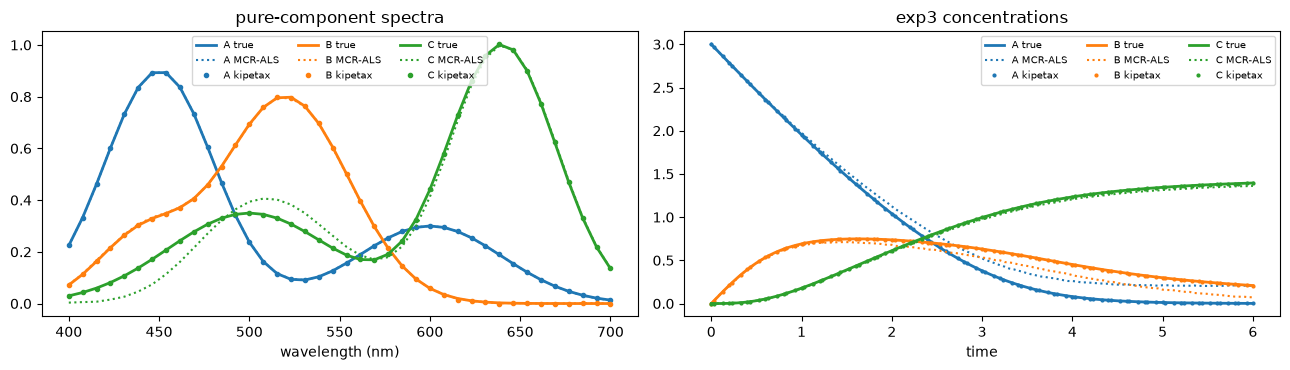

largest spectrum error, MCR-ALS: {'A': 0.001, 'B': 0.004, 'C': 0.097}
largest spectrum error, kipetax: {'A': np.float64(0.001), 'B': np.float64(0.004), 'C': np.float64(0.002)}


In [11]:
S_fit = final.experiments['exp1'].S[SPECIES]
Z3 = final.experiments['exp3'].Z
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for k in SPECIES:
    axes[0].plot(wl, S_true[k], '-', color=colors[k], lw=2, label=f'{k} true')
    axes[0].plot(wl, S_mcr[k], ':', color=colors[k], label=f'{k} MCR-ALS')
    axes[0].plot(S_fit.index, S_fit[k], 'o', ms=3, color=colors[k], label=f'{k} kipetax')
    axes[1].plot(t, C_true['exp3'][k], '-', color=colors[k], lw=2, label=f'{k} true')
    axes[1].plot(t, C_mcr['exp3'][k], ':', color=colors[k], label=f'{k} MCR-ALS')
    axes[1].plot(Z3.index, Z3[k], 'o', ms=2, color=colors[k], label=f'{k} kipetax')
axes[0].set(title='pure-component spectra', xlabel='wavelength (nm)')
axes[1].set(title='exp3 concentrations', xlabel='time')
for ax in axes:
    ax.legend(ncol=3, fontsize=7)
plt.tight_layout()
plt.show()
print('largest spectrum error, MCR-ALS:', dict(zip(SPECIES, (S_mcr - S_true).abs().max().round(3))))
print('largest spectrum error, kipetax:', dict(zip(SPECIES, (S_fit.values - S_true.values).__abs__().max(axis=0).round(3))))

## Summary and caveats

- **Curve resolution alone is ambiguous.** MCR-ALS reproduces the spectra to the
  noise level with distorted concentration profiles, and derivative-based
  discovery inherits the distortion.
- **The kinetic refit on raw spectra is what resolves it.** Fitting $D$ directly,
  with the kinetics and shared spectra estimated together, constrains the
  profiles enough to recover both the rate constants and the spectra.
- **Symbolic regression proposes; the spectral refit disposes.** jaxsr's job here
  is to suggest a small superset of plausible terms; pruning and trajectory BIC
  decide which survive.
- **Assumptions that matter:** known stoichiometry, known initial charges (they
  fix the absolute scale, which spectra alone cannot), several experiments with
  different compositions, and a candidate library that contains the right terms.
- **No confidence intervals yet:** `ReactionSet` does not compute a covariance.